<a href="https://colab.research.google.com/github/Prathamesh-kadam/LSST-Alert-Broker-/blob/main/Fink_lsst_data_transfer_mine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<img src="../../Fink_PrimaryLogo_WEB.jpg" width=400 />

# Use case: Manipulating outputs from the Data Transfer Service

The [Fink data transfer service](https://lsst.fink-portal.org/download) was developed due to the need to transfer large quantities of data for statistical and population studies, as well as to enable training of machine learning models (see [Fraga *et al*, 2024](https://www.aanda.org/articles/aa/full_html/2024/12/aa50370-24/aa50370-24.html)).

The service has been extensively used during its operation with ZTF data.

For LSST, we continue to provide the community with easy access to large volumes of data, however, the post-processing of the results requires some fine tunning, given the complexity of the survey.

You can discover details on how to fetch data from Fink in the documentation.

In this notebook, we provide you with a few examples on how to manipulate the resulting parquet files.

## Environment set up

In order to run this notebook, you will need to install the [fink-client](https://github.com/astrolabsoftware/fink-client) and [pyarrow](https://pypi.org/project/pyarrow/).

Then you can import the following libraries

In [3]:
!pip install fink-client

  Using cached fink_client-12.3.0-py3-none-any.whl.metadata (3.7 kB)
  Using cached rich_click-1.9.9-py3-none-any.whl.metadata (7.4 kB)
  Using cached confluent_kafka-2.16.1-cp313-cp313-manylinux_2_28_x86_64.whl.metadata (38 kB)
  Using cached fastavro-1.13.1-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (6.3 kB)
  Using cached polars-2.1.0-py3-none-any.whl.metadata (11 kB)
  Using cached polars_runtime_32-2.1.0-cp311-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (1.5 kB)
Using cached fink_client-12.3.0-py3-none-any.whl (55 kB)
Using cached fastavro-1.13.1-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl (3.6 MB)
Using cached confluent_kafka-2.16.1-cp313-cp313-manylinux_2_28_x86_64.whl (5.0 MB)
Using cached polars-2.1.0-py3-none-any.whl (911 kB)
Using cached polars_runtime_32-2.1.0-cp311-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (53.9 MB)
Using cached rich_click-1.9.9-py3-none-any.whl (

In [4]:
import numpy as np
import glob
import matplotlib.pylab as plt
import matplotlib
import pyarrow.parquet as pq
import pandas as pd

from fink_client.visualisation import extract_field
from fink_client.visualisation import show_stamps

# For plots
font = {
    'weight': 'bold',
    'size': 16
}

matplotlib.rc('font', **font)

### Case 1: Reading the data

Suppose that the result of your query to the data transfer service is store in a directory named ...

In [5]:
topicname = "ftransfer_lsst_2026-11-03_799186"

In [20]:
import glob

# Locate the downloaded metadata and the folder containing parquet files
metadata_files = glob.glob('../data/arrow_schema_ftransfer_lsst_*.metadata')
parquet_dirs = glob.glob('../data/ftransfer_lsst_*')

if metadata_files and parquet_dirs:
    schema_path = metadata_files[0]
    data_path = parquet_dirs[0]
    print(f"Loading schema from: {schema_path}")
    print(f"Loading data folder from: {data_path}")

    schema = pq.read_schema(schema_path)
    # Load the entire directory containing all downloaded partition files
    table = pq.read_table(data_path, schema=schema)
    print(f"Successfully loaded table with {len(table)} rows.")
else:
    raise FileNotFoundError("Required ftransfer metadata or parquet data files not found in '../data/'. Please run the download cell (4505357f) first.")

Loading schema from: ../data/arrow_schema_ftransfer_lsst_2026-11-03_799186.metadata
Loading data folder from: ../data/ftransfer_lsst_2026-11-03_799186
Successfully loaded table with 107 rows.


In [21]:
import requests
import os

repo_url = "https://api.github.com/repos/astrolabsoftware/fink-tutorials/git/trees/main?recursive=1"
response = requests.get(repo_url).json()

metadata_url = ""
parquet_urls = []

if 'tree' in response:
    for file_info in response['tree']:
        path = file_info['path']
        if 'arrow_schema' in path and 'metadata' in path:
            metadata_url = f"https://raw.githubusercontent.com/astrolabsoftware/fink-tutorials/main/{path}"
        if 'ftransfer_lsst_2026-03-27_750709' in path and path.endswith('.parquet'):
            parquet_urls.append(f"https://raw.githubusercontent.com/astrolabsoftware/fink-tutorials/main/{path}")

print("Found metadata URL:", metadata_url)
print(f"Found {len(parquet_urls)} parquet files to download.")

# Ensure output directories exist
os.makedirs('../data', exist_ok=True)
os.makedirs('../data/ftransfer_lsst_2026-11-03_799186', exist_ok=True)

# Clean up any existing files to avoid partition mixing
for f in os.listdir('../data/ftransfer_lsst_2026-11-03_799186'):
    os.remove(os.path.join('../data/ftransfer_lsst_2026-11-03_799186', f))

if metadata_url:
    r = requests.get(metadata_url)
    with open('../data/arrow_schema_ftransfer_lsst_2026-11-03_799186.metadata', 'wb') as f:
        f.write(r.content)
    print("Downloaded metadata.")

for url in parquet_urls:
    filename = url.split('/')[-1]
    r = requests.get(url)
    with open(f'../data/ftransfer_lsst_2026-11-03_799186/{filename}', 'wb') as f:
        f.write(r.content)
print(f"Successfully downloaded all {len(parquet_urls)} parquet partitions.")

Found metadata URL: https://raw.githubusercontent.com/astrolabsoftware/fink-tutorials/main/lsst/data_transfer/arrow_schema_ftransfer_lsst_2026-03-27_750709.metadata
Found 41 parquet files to download.
Downloaded metadata.
Successfully downloaded all 41 parquet partitions.


In [22]:
import os
# Locate the files in the directory to find the correct path
for root, dirs, files in os.walk('.'):
    for file in files:
        if 'arrow_schema' in file or 'ftransfer' in file:
            print(os.path.join(root, file))

You could easily get a pandas dataframe for convenience, although beware of cast for `diaObjectId` (see https://doc.lsst.fink-broker.org/services/data_transfer/#diaobjectid-casting-errors)

In [23]:
# Make a list of dict for easier manipulation
alerts = table.to_pylist()

In [24]:
len(alerts)

107

In [25]:
# check ids
for i in range(len(alerts)):
    objids = np.unique(extract_field(alerts[i], 'diaObjectId', current='diaSource', previous='prvDiaSources'))
    print(objids)

[313875416793743402]
[313853517453852677]
[313963405132693599]
[313980949159215215]
[313875416793743402]
[314011741898932229]
[0]
[170028528328769656]
[170050543393177677]
[313875415046815747]
[313980948078133302]
[0]
[0]
[0]
[170028510555406485]
[0]
[170112073841770544]
[0]
[0]
[313875416040865804]
[170046091945836650]
[170028500619100295]
[170028513830633513]
[170028517461852186]
[313998569250488348]
[313862203460550660]
[170028500566147171]
[313875416704090123]
[313853517735395444]
[170032910947582004]
[170028500581351556]
[170028510790287439]
[313853533295214686]
[0]
[170028500562477066]
[313875415090331669]
[313875415044194310]
[313985345528004656]
[170046091921195087]
[170028500619100295]
[313871016471822370]
[170112073818177974]
[170028536453660737]
[0]
[170046091723538510]
[170032916464664787]
[0]
[170112073817128991]
[0]
[313875416040865804]
[170050533130240451]
[170050533130764866]
[0]
[0]
[170050533138628729]
[170028511492833419]
[0]
[170028510514512021]
[313853517439697046]

### Case 2: accessing alert history

Now that your data is available as dictionaries, you are free to explore the potential of the alert package. Important things to keep in mind:

1.  An alert is one point --> `diaSource`
2.  The alert package contains the previous photometric history of that position --> `prvDiaSources` ...
3.  Starting from the second alert, it also contains 30 days of forced photometry preceeding the first alert --> `prvDiaForcedSources`

You can use any information contained in these fields for the construction of your model or filter.

Let's illustrate this task by separating 1 alert:

In [26]:
# Get one alert
alert = alerts[2]

You can explore the meaning of all fields in the schema page: https://lsst.fink-portal.org/schemas. In order to reconstruct the light curve from this, we will use the function below

Let's use it to gather the entire light curve information in a single data frame

In [27]:
mjds = extract_field(alert, 'midpointMjdTai', current="diaSource", previous="prvDiaSources")  # get observation days (MJD)
psfFlux = extract_field(alert, 'psfFlux', current="diaSource", previous="prvDiaSources")  # get difference fluxes
psfFluxErr = extract_field(alert, 'psfFluxErr', current="diaSource", previous="prvDiaSources")  # get difference flux errors
bands = extract_field(alert, 'band', current="diaSource", previous="prvDiaSources")  # get filter bands


We can now plot the entire photometric history for this source

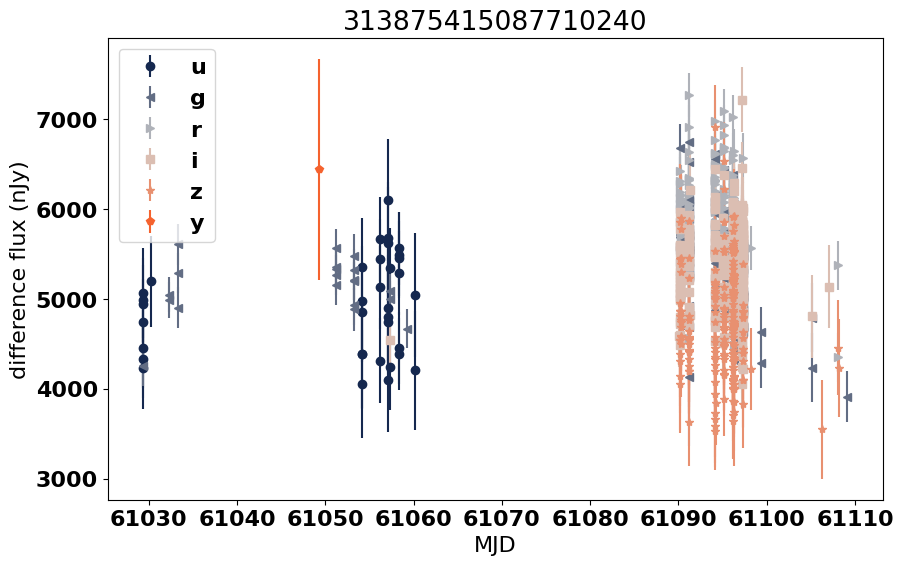

In [28]:
# all lsst bands
all_bands = ['u', 'g', 'r', 'i', 'z', 'y']
symbols = ['o', '<', '>', 's', '*', 'p']
colors = ["#15284f", "#626d84", "#afb2b9", "#dbbeb2", "#e89070", "#f5622e"]

# get unique filters
lc_bands = np.unique(bands)

plt.figure(figsize=(10, 6))
plt.title(objids[0])

for i in range(len(all_bands)):
    if all_bands[i] in lc_bands:
        # identify one filter at a time
        flag = bands == all_bands[i]
        plt.errorbar(mjds[flag], psfFlux[flag], yerr=psfFluxErr[flag], fmt=symbols[i], label=all_bands[i], color=colors[i])

plt.xlabel('MJD')
plt.ylabel('difference flux (nJy)')
plt.legend(loc='upper left')
plt.show()


you can also read with pandas

In [29]:
data_rubin = pd.read_parquet('../data/' + topicname)

Format the data

In [31]:
# get only the columns we need
objid = data_rubin['diaSource'].apply(lambda x: x['diaObjectId'] if x is not None else None)
flux = data_rubin['diaSource'].apply(lambda x: x['psfFlux'] if x is not None else None)
fluxerr = data_rubin['diaSource'].apply(lambda x: x['psfFluxErr'] if x is not None else None)
mjd = data_rubin['diaSource'].apply(lambda x: np.array(x['midpointMjdTai']) if x is not None else None)
band = data_rubin['diaSource'].apply(lambda x: x['band'] if x is not None else None)

# Safely handle potential None values in prvDiaSources
nobs = data_rubin['prvDiaSources'].apply(lambda x: x.shape[0] + 1 if x is not None else 1)
flux_prv = data_rubin['prvDiaSources'].apply(lambda x: np.array([x[i]['psfFlux'] for i in range(len(x))]) if x is not None else np.array([]))
fluxerr_prv = data_rubin['prvDiaSources'].apply(lambda x: np.array([x[i]['psfFluxErr'] for i in range(len(x))]) if x is not None else np.array([]))
mjd_prv = data_rubin['prvDiaSources'].apply(lambda x: np.array([x[i]['midpointMjdTai'] for i in range(len(x))]) if x is not None else np.array([]))
band_prv = data_rubin['prvDiaSources'].apply(lambda x: np.array([x[i]['band'] for i in range(len(x))]) if x is not None else np.array([]))

x_list = []
y_list = []
yerr_list = []
flt_list = []
for k in range(data_rubin.shape[0]):
    # concatenate history and current measurements safely
    curr_mjd = [mjd[k]] if mjd[k] is not None else []
    curr_flux = [flux[k]] if flux[k] is not None else []
    curr_fluxerr = [fluxerr[k]] if fluxerr[k] is not None else []
    curr_band = [band[k]] if band[k] is not None else []

    x_list.append(np.array(list(mjd_prv[k]) + curr_mjd))
    y_list.append(np.array(list(flux_prv[k]) + curr_flux))
    yerr_list.append(np.array(list(fluxerr_prv[k]) + curr_fluxerr))
    flt_list.append(np.array(list(band_prv[k]) + curr_band))

data_df = pd.DataFrame()
data_df['objid'] = objid
data_df['mjd'] = x_list
data_df['flux'] = y_list
data_df['fluxerr'] = yerr_list
data_df['band'] = flt_list

In [ ]:
data_df

,objid,mjd,flux,fluxerr,band
0,313761043604045880,"[61003.336679130254, 61004.30177726407, 61004....","[1007.5594482421875, 2069.40673828125, 2197.39...","[170.8847198486328, 157.63409423828125, 124.95...","[r, r, r, i, z, z, z, z, z, z, g, i, i, z, z, ..."
1,313761043604045880,"[61003.336679130254, 61004.30177726407, 61004....","[1007.5594482421875, 2069.40673828125, 2197.39...","[170.8847198486328, 157.63409423828125, 124.95...","[r, r, r, i, z, z, z, z, z, z, g, i, i, z, z, ..."
2,313673107053215773,"[60983.202726822914, 60983.20361924672, 60984....","[16812.291015625, 17901.390625, 23432.30078125...","[649.7747802734375, 645.759033203125, 524.2481...","[g, g, r, r, g, g, g, g, r, r, g, g, g, g, g, ..."
3,313761043604045880,"[61003.336679130254, 61004.30177726407, 61004....","[1007.5594482421875, 2069.40673828125, 2197.39...","[170.8847198486328, 157.63409423828125, 124.95...","[r, r, r, i, z, z, z, z, z, z, g, i, i, z, z, ..."
4,313673107053215773,"[60983.202726822914, 60983.20361924672, 60984....","[16812.291015625, 17901.390625, 23432.30078125...","[649.7747802734375, 645.759033203125, 524.2481...","[g, g, r, r, g, g, g, g, r, r, g, g, g, g, g, ..."
5,313761043604045880,"[61003.336679130254, 61004.30177726407, 61004....","[1007.5594482421875, 2069.40673828125, 2197.39...","[170.8847198486328, 157.63409423828125, 124.95...","[r, r, r, i, z, z, z, z, z, z, g, i, i, z, z, ..."
6,313761043604045880,"[61003.336679130254, 61004.30177726407, 61004....","[1007.5594482421875, 2069.40673828125, 2197.39...","[170.8847198486328, 157.63409423828125, 124.95...","[r, r, r, i, z, z, z, z, z, z, g, i, i, z, z, ..."
7,313761043604045880,"[61003.336679130254, 61004.30177726407, 61004....","[1007.5594482421875, 2069.40673828125, 2197.39...","[170.8847198486328, 157.63409423828125, 124.95...","[r, r, r, i, z, z, z, z, z, z, g, i, i, z, z, ..."
8,313673107053215773,"[60983.202726822914, 60983.20361924672, 60984....","[16812.291015625, 17901.390625, 23432.30078125...","[649.7747802734375, 645.759033203125, 524.2481...","[g, g, r, r, g, g, g, g, r, r, g, g, g, g, g, ..."
9,313673107053215773,"[60983.202726822914, 60983.20361924672, 60984....","[16812.291015625, 17901.390625, 23432.30078125...","[649.7747802734375, 645.759033203125, 524.2481...","[g, g, r, r, g, g, g, g, r, r, g, g, g, g, g, ..."
